# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('plans.csv')
users = pd.read_csv('users_latam.csv')
usage = pd.read_csv('usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      str    
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), str(1)
memory usage: 260.0 bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     4000 non-null   int64
 1   first_name  4000 non-null   str  
 2   last_name   4000 non-null   str  
 3   age         4000 non-null   int64
 4   city        3531 non-null   str  
 5   reg_date    4000 non-null   str  
 6   plan        4000 non-null   str  
 7   churn_date  466 non-null    str  
dtypes: int64(2), str(6)
memory usage: 250.1 KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  str    
 3   date      39950 non-null  str    
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.8 MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
pd.DataFrame({
    'nulos': users.isna().sum(),
    'proporcion': users.isna().mean().round(3)
})

,nulos,proporcion
user_id,0,0.000
first_name,0,0.000
last_name,0,0.000
age,0,0.000
city,469,0.117
reg_date,0,0.000
plan,0,0.000
churn_date,3534,0.884


In [11]:
# cantidad de nulos para usage
pd.DataFrame({
    'nulos': usage.isna().sum(),
    'proporcion': usage.isna().mean().round(3)
})

,nulos,proporcion
id,0,0.000
user_id,0,0.000
type,0,0.000
date,50,0.001
duration,22076,0.552
length,17896,0.447


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción? 
- Indica qué harías: ¿imputar, eliminar, ignorar? 

Dataset **users**
- `city` (469 nulos, ~12%): **imputar** con la categoría `"Desconocida"`. No se puede deducir la ciudad real, y eliminar esas filas haría perder ~12% de los clientes junto con todo su uso. También se reemplaza el valor `"?"` por la misma categoría.
- `churn_date` (3,534 nulos, ~88%): **ignorar**. El nulo significa que el cliente sigue activo, no que falte información. Se crea una columna `churned` (True/False) para analizar el abandono.

Datset **usage**
- `duration` (~55%) y `length` (~45%): **ignorar**. Son nulos estructurales: los mensajes no tienen duración y las llamadas no tienen longitud.
- `date` (50 nulos, 0.1%): **ignorar**. El porcentaje es mínimo, así que se conservan esos registros para contar llamadas y mensajes, y solo se excluyen del análisis por fechas.

**Conclusión:** no se elimina ningún registro. Solo se imputa `city` con una categoría explícita.




### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print(users[['user_id', 'age']].describe().round(3))
print("número de registros == -999:", (users['age'] == -999).sum())
print("edad minima:", users[users['age'] > -999]["age"].min())


         user_id       age
count   4000.000  4000.000
mean   11999.500    33.740
std     1154.845   123.232
min    10000.000  -999.000
25%    10999.750    32.000
50%    11999.500    47.000
75%    12999.250    63.000
max    13999.000    79.000
número de registros == -999: 55
edad minima: 18


- La columna `user_id` es un identificador, por lo que no tiene sentido interpretar su promedio; lo importante es que sea único y sin saltos. Los valores van de 10,000 a 13,999, es decir, exactamente 4,000 valores, igual al `count`, y la media cae justo en el centro del rango, lo que indica una secuencia consecutiva. Con `.nunique()` se confirma que no hay IDs repetidos. **No se encontraron valores inválidos ni sentinels.**

- La columna `age` presenta una dispersión anormal (`std` = 123) causada por el valor sentinel `-999`, que aparece en 55 registros (~1.4% de los clientes). Este valor distorsiona las estadísticas: la media (33.7) queda muy por debajo de la mediana (47). Excluyendo el sentinel, el rango real de edades es de 18 a 79 años, lo cual es coherente para clientes de telecomunicaciones. **En la limpieza, el `-999` se reemplazará por la mediana de las edades válidas**, calculada excluyendo el sentinel para que no sesgue el valor de reemplazo. Se elige la mediana y no la media porque es más robusta ante valores extremos. **Limitación:** los 55 clientes imputados (~48 años) quedarán en el grupo de edad 45–59, lo que puede inflar ligeramente ese segmento; al ser solo el 1.4% de la base, el impacto en las conclusiones es menor.

In [13]:
# explorar columnas numéricas de usage

print(usage[["id", "user_id"]].describe().round(3))

print("ids unicos:", usage["id"].nunique())
print("user_id unicos:", usage["user_id"].nunique())
(~usage['user_id'].isin(users['user_id'])).sum()


             id    user_id
count  40000.00  40000.000
mean   20000.50  12002.406
std    11547.15   1157.280
min        1.00  10000.000
25%    10000.75  10996.000
50%    20000.50  12013.000
75%    30000.25  13005.000
max    40000.00  13999.000
ids unicos: 40000
user_id unicos: 3999


np.int64(0)

In [14]:
print(usage[['duration', 'length']].describe(percentiles=[.75, .99, .999]).round(3))
print('duration = 120:', (usage['duration'] == 120).sum())
print('length = 1490:', (usage['length'] == 1490).sum())
print('Mensajes con duration:', usage.query("type == 'text'")['duration'].notna().sum())
print('Llamadas con length:', usage.query("type == 'call'")['length'].notna().sum())
print('Llamadas de 0 min:', ((usage['type'] == 'call') & (usage['duration'] == 0)).sum())
print('Mensajes vacíos:', ((usage['type'] == 'text') & (usage['length'] == 0)).sum())


        duration     length
count  17924.000  22104.000
mean       5.202     52.127
std        6.843     56.611
min        0.000      0.000
75%        6.990     64.000
99%       23.691     97.000
99.9%    120.000   1490.000
max      120.000   1490.000
duration = 120: 30
length = 1490: 30
Mensajes con duration: 16
Llamadas con length: 12
Llamadas de 0 min: 15
Mensajes vacíos: 133


- Las columnas `id` y `user_id` son identificadores. En `id` hay 40,000 valores únicos, igual al total de registros, por lo que cada evento tiene su propio identificador. En `user_id` se verificó que todos los clientes con uso existen en `users`; hay 3,999 clientes distintos con eventos frente a 4,000 registrados, es decir, solo un cliente no tiene uso registrado. **No se encontraron valores inválidos ni sentinels en estas columnas.**

- Las columnas `duration` y `length` presentan valores máximos muy alejados del resto de la distribución. En `duration`, el 75% de las llamadas dura menos de 7 minutos y el percentil 99 es de ~24 minutos, pero el máximo es de 120. En `length`, el 75% de los mensajes tiene menos de 64 caracteres y el percentil 99 es de 97, pero el máximo es de 1,490. Estos valores aparecen exactamente 30 veces cada uno, siempre con el mismo valor, por lo que se consideran **sentinels (códigos de error) y no uso real**. Esto también explica la `std` inflada de `length` (56.6) frente a una mediana de 50.
  - Además, 16 mensajes tienen valor en `duration` y 12 llamadas tienen valor en `length`, es decir, **datos en la columna equivocada** según el tipo de evento.
  - Hay 15 llamadas de 0 minutos y 133 mensajes de 0 caracteres. No son necesariamente errores (pueden ser llamadas no contestadas o mensajes vacíos), por lo que se conservan pero se marcan para revisión.
  - **En la limpieza**, los sentinels y los valores en la columna equivocada se convertirán en nulos (`NaN`).

In [15]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(users[col].value_counts(dropna=False))
    print()

city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: count, dtype: int64

plan
Basico     2595
Premium    1405
Name: count, dtype: int64



- La columna `city` contiene 6 ciudades válidas: 3 de Colombia (Bogotá, Medellín, Cali) y 3 de México (CDMX, GDL, MTY), escritas de forma consistente. Sin embargo, el valor `?` (96 registros) es un **sentinel** que representa una ciudad desconocida y no se detectó como nulo en el paso anterior. Sumado a los 469 `NaN`, hay 565 clientes (~14%) sin ciudad identificada. **En la limpieza, ambos casos se agruparán en la categoría `"Desconocida"`.**

- La columna `plan` solo tiene dos valores, `Basico` (2,595) y `Premium` (1,405), que coinciden exactamente con `plan_name` en `plans`. **No se encontraron valores inválidos**, por lo que ambas tablas se pueden unir sin ajustes.

In [16]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

type
text    22092
call    17908
Name: count, dtype: int64

- La columna `type` tiene 40,000 registros sin nulos y solo dos valores válidos: `text` (22,092, ~55%) y `call` (17,908, ~45%), escritos de forma consistente. **No se encontraron valores inválidos ni sentinels.** Esta columna explica los nulos estructurales de `duration` y `length`: las llamadas solo registran duración y los mensajes solo longitud.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

**Valores inválidos o sentinels**

**Dataset `users`**
- **`age`**: el valor `-999` aparece en 55 registros (~1.4%). No es una edad posible y distorsiona las estadísticas (media 33.7 frente a mediana 47, `std` de 123). Excluyéndolo, el rango real es de 18 a 79 años.
  → **Acción:** convertir a nulo (`NaN`). No se imputa porque la edad se usará para segmentar; asignar la media o mediana (~48 años) concentraría artificialmente a estos clientes en el grupo 45–59.
- **`city`**: el valor `?` aparece en 96 registros y representa una ciudad desconocida, aunque no se detecta como nulo. Sumado a los 469 `NaN`, hay 565 clientes (~14%) sin ciudad.
  → **Acción:** agrupar `?` y `NaN` en la categoría `"Desconocida"`, para conservar a estos clientes en el análisis sin inventarles una ubicación.

**Dataset `usage`**
- **`duration`**: el valor `120` aparece exactamente 30 veces, muy lejos del resto de la distribución (percentil 99 ≈ 24 min).
  → **Acción:** tratarlo como sentinel y convertirlo a nulo (`NaN`).
- **`length`**: el valor `1490` aparece exactamente 30 veces, muy lejos del resto (percentil 99 = 97 caracteres).
  → **Acción:** tratarlo como sentinel y convertirlo a nulo (`NaN`).
- **Datos en la columna equivocada**: 16 mensajes tienen valor en `duration` y 12 llamadas tienen valor en `length`.
  → **Acción:** convertir esos valores a nulo, ya que no corresponden al tipo de evento.
- **Llamadas de 0 minutos (15) y mensajes de 0 caracteres (133)**: no son necesariamente errores; pueden ser llamadas no contestadas o mensajes vacíos.
  → **Acción:** conservarlos y marcarlos con una columna indicadora para revisión.

**Columnas sin problemas**
- `user_id` e `id` son únicos y consistentes, y todos los `user_id` de `usage` existen en `users`.
- `plan` coincide exactamente con `plans`, y `type` solo tiene los valores `call` y `text`.

**Conclusión:** ningún problema justifica eliminar registros. Todos se resuelven convirtiendo a nulo o agrupando en una categoría, lo que conserva el uso de todos los clientes en el análisis.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])


In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [19]:
# Revisar los años presentes en `reg_date` de users
years= users["reg_date"].dt.year.unique()


for year in years:
    print(year, (users["reg_date"].dt.year == year).sum())


print(users[users["reg_date"].dt.year >2024]["reg_date"].unique())

2022 1314
2026 40
2023 1316
2024 1330
<DatetimeArray>
['2026-05-10 00:00:00']
Length: 1, dtype: datetime64[ns]


En `reg_date`, En `reg_date`, la columna se convirtió a tipo fecha y se revisaron los años presentes: 2022 (1,314), 2023 (1,316), 2024 (1,330) y **2026 (40)**. Los registros de 2026 son inválidos por tres razones:

- **Están fuera del periodo del dataset:** los datos de uso son de enero a junio de 2024 y las bajas llegan hasta diciembre de 2024, por lo que no puede haber clientes registrados en 2026.
- **Hay un salto en la secuencia:** no existe ningún registro de 2025, lo que descarta que sean altas reales de una continuación natural.
- **Todos tienen la misma fecha exacta (`2026-05-10 00:00:00`)**, mientras que en los años válidos cada cliente tiene una fecha y hora distinta.

Por eso se considera un **valor sentinel** que afecta a 40 clientes (1% del total). **Acción:** convertir solo esa fecha a nulo (`NaT`) en lugar de eliminar los registros, ya que el resto de la información de estos clientes (edad, ciudad, plan y uso) es válida. Es el mismo criterio aplicado a `age`.


In [20]:
# Revisar los años presentes en `date` de usage


years= usage["date"].dt.year.unique()


for year in years:
    print(year, (usage["date"].dt.year == year).sum())

print(usage[usage["date"].dt.year >2024]["date"].unique())


2024.0 39950
nan 0
<DatetimeArray>
[]
Length: 0, dtype: datetime64[ns]


En `date`, todos los eventos con fecha válida corresponden a **2024** (39,950 registros), entre el 1 de enero y el 30 de junio, es decir, un periodo de 6 meses. No aparecen años fuera de rango. Los únicos valores problemáticos son los **50 eventos sin fecha** (`NaT`, 0.1% del total); aparecen como `nan` con conteo 0 porque un nulo nunca es igual a otro valor en una comparación. Sumados a los 39,950, completan los 40,000 eventos.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**

- **¿Aparecen años imposibles?**
  - **`users` – `reg_date`:** sí. Hay 40 registros con fecha **2026-05-10**, un año que aún no había transcurrido al momento de guardar los datos (el dataset no tiene información posterior a diciembre de 2024). Además, todos tienen la misma fecha exacta y no hay registros de 2025, por lo que se trata de un valor sentinel.
  - **`usage` – `date`:** no. Todos los eventos con fecha son de 2024, entre enero y junio. Solo hay 50 eventos sin fecha (0.1%).
  - **Años muy antiguos:** no se encontraron. Las fechas de registro más antiguas son de enero de 2022, lo cual es coherente.

- **¿Qué harías con ellas?**
  - **`reg_date` de 2026:** convertir esas fechas a nulo (`NaT`) y conservar a los 40 clientes, ya que el resto de su información (edad, ciudad, plan y uso) es válida. Es el mismo criterio aplicado a `age`.
  - **`date` sin valor:** conservar esos 50 eventos para las métricas de volumen (llamadas, minutos, mensajes) y excluirlos únicamente de los análisis por fecha.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] > -999]["age"].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))
print('Nulos en city:', users['city'].isna().sum())

city
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: count, dtype: int64
Nulos en city: 565


In [23]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print('Fechas nulas en reg_date:', users['reg_date'].isna().sum())
print('Fecha mínima:', users['reg_date'].min())
print('Fecha máxima:', users['reg_date'].max())

Fechas nulas en reg_date: 40
Fecha mínima: 2022-01-01 00:00:00
Fecha máxima: 2024-12-31 00:00:00


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
pd.crosstab(usage['type'], usage['duration'].isna())

duration,False,True
type,,
call,17908,0
text,16,22076


In [25]:
# Verificación MAR en usage (Missing At Random) para length
pd.crosstab(usage['type'], usage['length'].isna())

length,False,True
type,,
call,12,17896
text,22092,0


**Diagnóstico de nulos en `duration` y `length`**

Se cruzó cada columna con `type` para verificar si los nulos dependen del tipo de evento:

| Columna | `call` (nulos) | `text` (nulos) |
|---|---|---|
| `duration` | 0 de 17,908 (0%) | 22,076 de 22,092 (~100%) |
| `length` | 17,896 de 17,908 (~100%) | 0 de 22,092 (0%) |

- Los nulos de **`duration`** se concentran por completo en los mensajes, y los de **`length`** en las llamadas. La ausencia de datos **depende de la columna `type`**, por lo que se confirma que son **MAR (Missing At Random)**.
- Son nulos **estructurales**: un mensaje no tiene duración y una llamada no tiene longitud. No falta información que se pueda recuperar.
- **Decisión: dejarlos como nulos.** Imputarlos (por ejemplo, con la media) sería inventar duraciones para mensajes y longitudes para llamadas, lo que distorsionaría las métricas de uso. Los análisis se harán filtrando por tipo de evento: `duration` solo para llamadas y `length` solo para mensajes.
- **Excepción detectada:** 16 mensajes tienen valor en `duration` y 12 llamadas tienen valor en `length`. No son nulos, sino datos en la columna equivocada, por lo que se convertirán a nulo para mantener la consistencia con el tipo de evento.

In [26]:
# Corregir datos en la columna equivocada
usage.loc[usage['type'] == 'text', 'duration'] = np.nan
usage.loc[usage['type'] == 'call', 'length'] = np.nan

# Corregir sentinels
usage['duration'] = usage['duration'].replace(120, np.nan)
usage['length'] = usage['length'].replace(1490, np.nan)

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby(['user_id']).agg({"is_text":"sum", "is_call":"sum", "duration":"sum"}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes", "is_call":"cant_llamadas","duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]] = user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].fillna(0)
user_profile.head(5)



,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [30]:
# Revisar si los sentinels de duration y length siguen en usage
print('Máximo duration:', usage['duration'].max())
print('Máximo length:', usage['length'].max())
print('duration = 120:', (usage['duration'] == 120).sum())
print('length = 1490:', (usage['length'] == 1490).sum())
print()
print(pd.crosstab(usage['type'], usage['duration'].notna()))

Máximo duration: 46.98
Máximo length: 125.0
duration = 120: 0
length = 1490: 0

duration  False  True 
type                  
call         14  17894
text      22092      0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [31]:
# Resumen estadístico de las columnas 

user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe().round(2)


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.00,4000.00,4000.00,4000.00
mean,48.14,5.52,4.48,22.41
std,17.69,2.36,2.15,15.05
min,18.00,0.00,0.00,0.00
25%,33.00,4.00,3.00,11.08
50%,48.00,5.00,4.00,19.67
75%,63.00,7.00,6.00,30.99
max,79.00,17.00,15.00,105.54


In [32]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True)*100).round(2)

plan
Basico     64.88
Premium    35.12
Name: proportion, dtype: float64

**Diagnóstico del resumen estadístico por usuario (2024)**

**Columnas numéricas**
- **`age`:** las edades van de 18 a 79 años, con media (48.1) y mediana (48) prácticamente iguales, lo que indica una distribución simétrica sin valores extremos. Tras imputar el sentinel `-999`, la `std` bajó de 123 a 17.7, un valor coherente.
- **`cant_mensajes`:** en promedio, cada cliente envió 5.5 mensajes en el semestre (mediana 5), con un rango de 0 a 17. El uso es bajo y parejo.
- **`cant_llamadas`:** en promedio, 4.5 llamadas por cliente (mediana 4), con un rango de 0 a 15.
- **`cant_minutos_llamada`:** en promedio, 22.4 minutos por cliente en el semestre (mediana 19.7). La media supera a la mediana y el máximo (105.5) está muy alejado del percentil 75 (31), lo que indica una **cola de clientes con uso alto** que se analizará en la sección de outliers.
- Los mínimos de 0 corresponden al cliente sin uso registrado, que se conservó en el análisis con valores en cero.

**Columna categórica**
- **`plan`:** el 64.9% de los clientes tiene el plan **Básico** y el 35.1% el **Premium**. Hay casi dos clientes Básico por cada Premium, por lo que en las comparaciones entre planes conviene usar promedios o proporciones, no totales.

**Conclusión:** tras la limpieza, los datos no presentan valores imposibles. El uso general es bajo (unos 4 minutos y 1 mensaje al mes por cliente), y la única señal de valores extremos está en los minutos de llamada.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

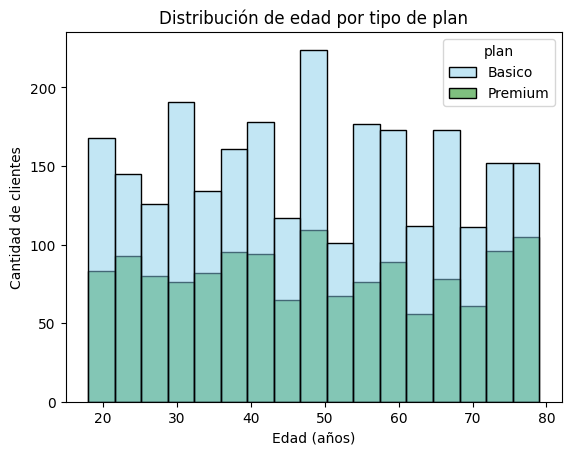

In [33]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x="age", hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de edad por tipo de plan')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de clientes')
plt.show()

💡 **Insights:**
- **Tipo de distribución:** la edad tiene una distribución **aproximadamente uniforme** entre 18 y 79 años. No es simétrica en forma de campana ni está sesgada; los clientes se reparten de forma pareja en todos los rangos de edad.
- **Por plan:** el plan Básico tiene más clientes en todos los rangos, lo cual es esperable porque representa el 65% de la base. La proporción entre Básico y Premium se mantiene parecida en todas las edades, así que **no existe un patrón de edad asociado al tipo de plan**: jóvenes y mayores eligen Premium en proporciones similares.
- **Efecto de la imputación:** la barra cercana a los 48 años sobresale del resto porque ahí se concentran los 55 clientes cuya edad se imputó con la mediana. Es un pico artificial, no un comportamiento real, y confirma la limitación documentada en la limpieza.

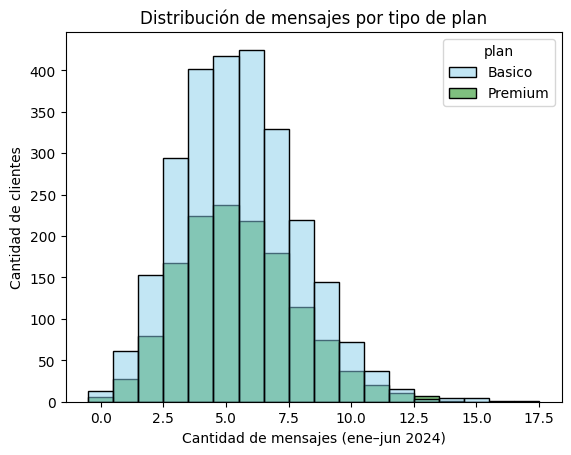

In [34]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes (ene–jun 2024)')
plt.ylabel('Cantidad de clientes')
plt.show()

💡 **Insights:**
- **Tipo de distribución:** la cantidad de mensajes por cliente tiene una distribución **ligeramente sesgada a la derecha**. La mayoría de los clientes envió entre 3 y 8 mensajes en el semestre, con el pico entre 4 y 6, y una cola corta de pocos clientes que llegan a 12–17 mensajes.
- **Por plan:** Básico y Premium tienen **la misma forma de distribución**, con el pico en los mismos valores. Los usuarios Premium no envían más mensajes que los Básico, a pesar de tener 5 veces más mensajes incluidos (500 vs. 100). **No existe un patrón de uso diferenciado por plan.**
- **Uso frente al plan:** con unos 5–6 mensajes en 6 meses (menos de 1 al mes), el uso real está muy por debajo de lo incluido en cualquiera de los dos planes.

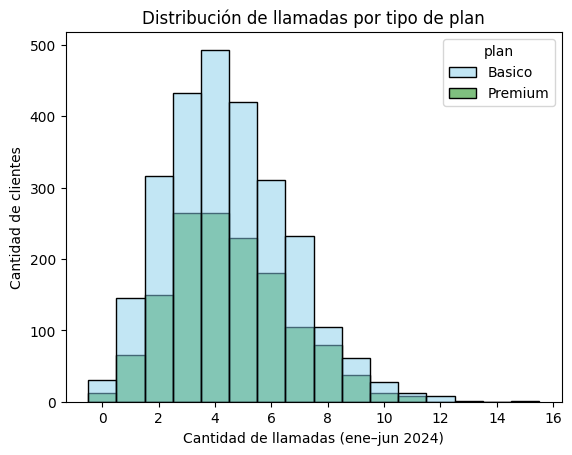

In [35]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data=user_profile, x="cant_llamadas", hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas (ene–jun 2024)')
plt.ylabel('Cantidad de clientes')
plt.show()

💡 **Insights:**
- **Tipo de distribución:** la cantidad de llamadas por cliente tiene una distribución **ligeramente sesgada a la derecha**. La mayoría de los clientes hizo entre 2 y 7 llamadas en el semestre, con el pico en 4, y una cola de pocos clientes que llegan a 12–15 llamadas.
- **Por plan:** Básico y Premium tienen **la misma forma de distribución** y el pico en el mismo valor. Los usuarios Premium no hacen más llamadas que los Básico. **No existe un patrón de uso diferenciado por plan.**
- **Uso frente al plan:** con unas 4–5 llamadas en 6 meses (menos de una al mes), la frecuencia de llamadas es muy baja para ambos planes.

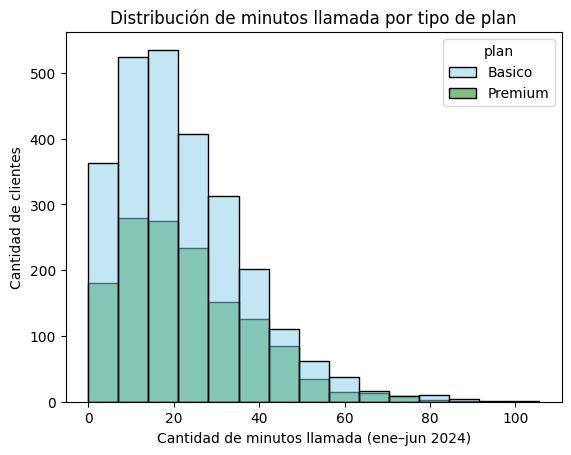

In [36]:
# Histograma para visualizar la cant_minutos_llamada


sns.histplot(data=user_profile, x="cant_minutos_llamada", hue='plan', palette=['skyblue', 'green'], bins=15)
plt.title('Distribución de minutos llamada por tipo de plan')
plt.xlabel('Cantidad de minutos llamada (ene–jun 2024)')
plt.ylabel('Cantidad de clientes')
plt.show()

💡 **Insights:**
- **Tipo de distribución:** los minutos totales de llamada por cliente tienen una distribución **sesgada a la derecha**, más marcada que en mensajes y llamadas. La mayoría de los clientes acumuló entre 5 y 35 minutos en el semestre, con el pico entre 10 y 20, y una cola larga de pocos clientes que superan los 60 minutos y llegan hasta ~105. Por eso la media (22.4) es mayor que la mediana (19.7).
- **Por plan:** Básico y Premium tienen **la misma forma de distribución**, con el pico en los mismos valores y una cola similar. Los usuarios Premium no hablan más minutos que los Básico, aunque su plan incluye 6 veces más minutos (600 vs. 100). **No existe un patrón de uso diferenciado por plan.**
- **Uso frente al plan:** incluso los clientes de la cola, con ~105 minutos en 6 meses (unos 17 al mes), quedan muy por debajo de los 100 minutos mensuales del plan Básico. Los clientes de uso alto se revisarán en la sección de outliers.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

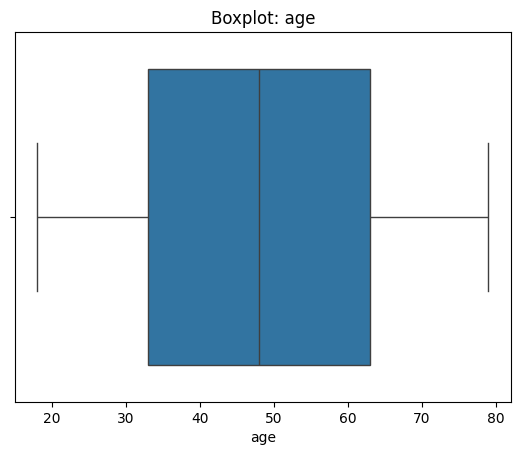

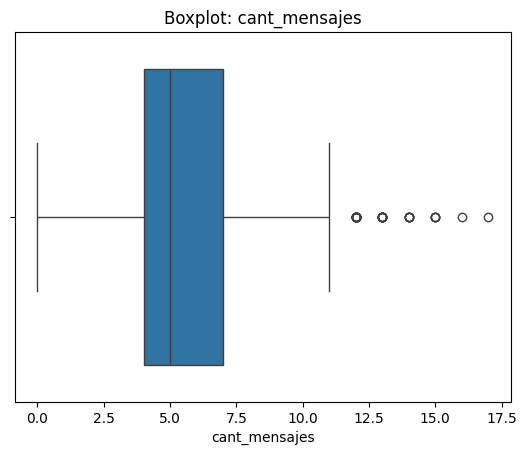

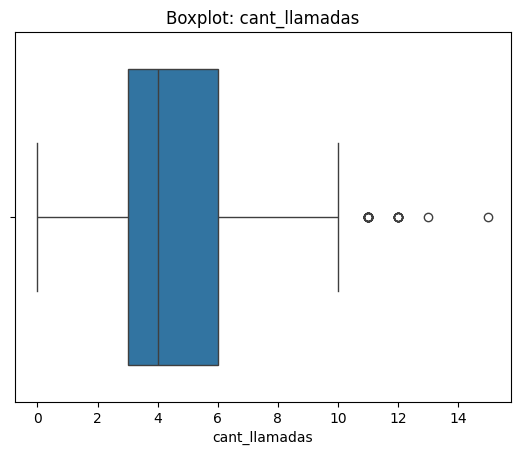

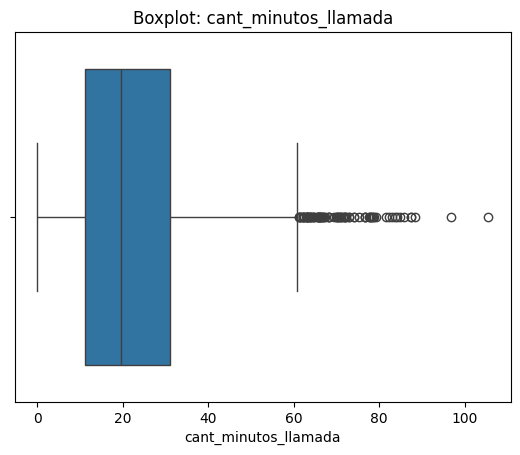

In [37]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas: 
    sns.boxplot(data=user_profile, x=col) 
    plt.title(f'Boxplot: {col}')
    plt.show()

💡 **Insights:**
- **`age`:** **no presenta outliers.** Todos los valores están dentro de los bigotes (18–79 años) y la mediana (48) queda centrada en la caja, lo que confirma una distribución simétrica.
- **`cant_mensajes`:** **presenta outliers solo del lado derecho.** Unos pocos clientes enviaron entre 12 y 17 mensajes, por encima del límite superior. No hay outliers en valores bajos.
- **`cant_llamadas`:** **presenta outliers solo del lado derecho.** Algunos clientes hicieron entre 11 y 15 llamadas, por encima del límite superior.
- **`cant_minutos_llamada`:** **presenta la mayor cantidad de outliers, todos del lado derecho.** Hay una cola de clientes que superan los ~60 minutos en el semestre y llegan hasta ~105, coherente con el sesgo a la derecha del histograma.

En las tres variables de uso, los outliers son **solo superiores**, así que basta con calcular el límite superior del método IQR.

In [38]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1 
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(col, '| Límite superior:', round(limite_superior, 2), '| Outliers:', n_outliers)






cant_mensajes | Límite superior: 11.5 | Outliers: 46
cant_llamadas | Límite superior: 10.5 | Outliers: 30
cant_minutos_llamada | Límite superior: 60.86 | Outliers: 84


In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.411225
std,2.359738,2.145139,15.053351
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.080000
50%,5.000000,4.000000,19.670000
75%,7.000000,6.000000,30.992500
max,17.000000,15.000000,105.540000


**Límites IQR y decisión sobre outliers**

| Variable | Límite superior | Outliers | % de clientes |
|---|---|---|---|
| `cant_mensajes` | 11.5 mensajes | 46 | 1.2% |
| `cant_llamadas` | 10.5 llamadas | 30 | 0.8% |
| `cant_minutos_llamada` | 60.86 minutos | 84 | 2.1% |

- Solo se calculó el **límite superior** porque, como se vio en los boxplots, los outliers están únicamente del lado derecho. `age` no se incluyó porque no presenta outliers.
- Los outliers representan entre el 0.8% y el 2.1% de los clientes, una proporción pequeña.
- **No son errores de registro:** los sentinels (`120`, `1490`) ya se limpiaron, y los valores restantes son realistas. Por ejemplo, el cliente con más minutos (~105 en 6 meses) habla unos 17 minutos al mes, muy por debajo de los 100 minutos del plan Básico. Tampoco hay señales evidentes de fraude.

**Decisión: conservar los outliers.** Representan clientes reales con uso más intenso que el promedio, y eliminarlos sesgaría el análisis hacia abajo y ocultaría justo el segmento de mayor consumo, relevante para el diseño de planes. Si un análisis posterior requiere métricas robustas, se puede usar la mediana en lugar de la media.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = "Alto uso"
user_profile.loc[(user_profile['cant_llamadas']<10) & (user_profile['cant_mensajes']<10), 'grupo_uso'] = "Uso medio"
user_profile.loc[(user_profile['cant_llamadas']<5) & (user_profile['cant_mensajes']<5), 'grupo_uso'] = "Bajo uso"

In [41]:
# verificar cambios
user_profile.head()
user_profile['grupo_uso'].value_counts()

grupo_uso
Uso medio    2943
Bajo uso      779
Alto uso      278
Name: count, dtype: int64

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = "Adulto Mayor"
user_profile.loc[(user_profile['age']<60), 'grupo_edad'] = "Adulto"
user_profile.loc[(user_profile['age']<30), 'grupo_edad'] = "Joven"

In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

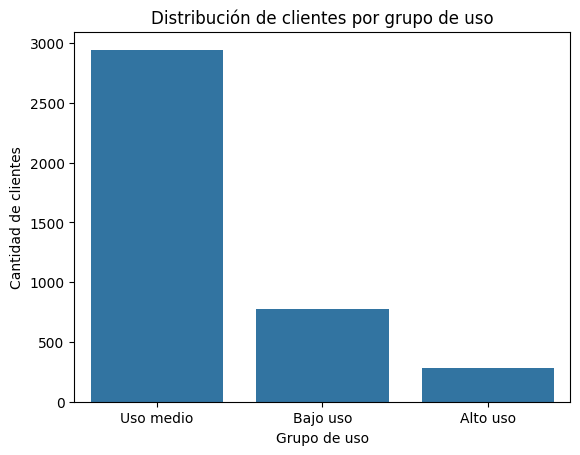

In [44]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order= ['Uso medio', 'Bajo uso', 'Alto uso'])
plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de clientes')
plt.show()

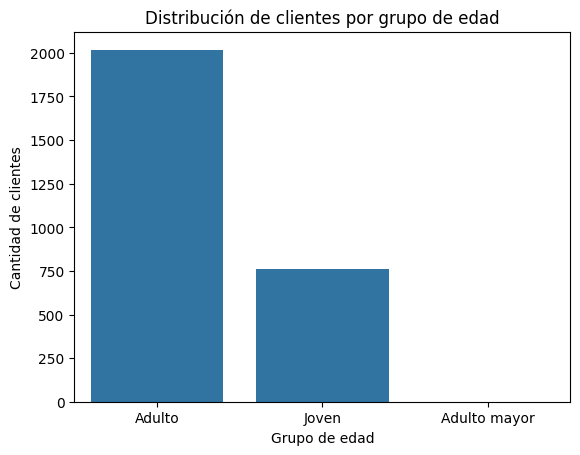

In [45]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile, x='grupo_edad', order= ['Adulto', 'Joven', 'Adulto mayor'])
plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.show()


In [46]:
user_profile.groupby('grupo_edad')[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean().round(2)

,cant_mensajes,cant_llamadas,cant_minutos_llamada
grupo_edad,,,
Adulto,5.55,4.48,22.57
Adulto Mayor,5.49,4.50,22.10
Joven,5.52,4.43,22.49



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- **`age`:** 55 registros (1.4%) con el valor sentinel `-999`. Se imputaron con la mediana de las edades válidas (48 años).
- **`city`:** 565 clientes (14.1%) sin ciudad: 469 nulos y 96 con el valor `?`. Se convirtieron todos a nulo.
- **`reg_date`:** 40 registros (1%) con una fecha imposible (2026-05-10), posterior al periodo de los datos. Se convirtieron a nulo.
- **`churn_date`:** las 466 fechas de baja venían en notación científica con coma decimal, en lugar de formato de fecha.
- **`duration` y `length`:** 30 sentinels en cada columna (`120` minutos y `1490` caracteres) y 28 valores en la columna equivocada (16 mensajes con duración y 12 llamadas con longitud). Se convirtieron a nulo; sin esta limpieza, los minutos por cliente quedaban inflados.
- **`date`:** 50 eventos (0.1%) sin fecha, que se conservaron para las métricas de volumen.
- Los nulos de `duration` (55%) y `length` (45%) son **estructurales (MAR)**: los mensajes no tienen duración y las llamadas no tienen longitud.

🔍 **Segmentos por Edad**
- **Adulto (30–59 años):** el grupo más grande, con 2,018 clientes (50.5%).
- **Adulto Mayor (60+):** 1,222 clientes (30.6%), casi un tercio de la base.
- **Joven (18–29):** 760 clientes (19.0%).
- El uso de llamadas y mensajes es **prácticamente igual en los tres grupos de edad**: todos promedian entre 5.5 y 5.6 mensajes, 4.4 y 4.5 llamadas, y 22 y 23 minutos en el semestre. La edad no explica diferencias de consumo.

📊 **Segmentos por Nivel de Uso**
- **Uso medio:** 2,943 clientes (73.6%), con menos de 10 llamadas y menos de 10 mensajes en el semestre.
- **Bajo uso:** 779 clientes (19.5%), con menos de 5 llamadas y menos de 5 mensajes.
- **Alto uso:** 278 clientes (7.0%), con 10 o más llamadas o mensajes.
- **Outliers:** solo de valores altos, entre el 0.8% y el 2.1% de los clientes según la variable (hasta ~105 minutos y 17 mensajes en 6 meses). No son errores ni señales de fraude, sino clientes con uso más intenso, y se conservaron.

➡️ **Esto sugiere que** el comportamiento de uso es muy homogéneo: no varía según la edad ni según el plan. Los clientes Premium usan lo mismo que los Básico, aunque pagan más del doble (USD 25 vs. USD 12) y tienen 6 veces más minutos incluidos. Además, el uso real está muy por debajo de lo que incluyen los planes: el cliente promedio usa unos 4 minutos y 1 mensaje al mes, frente a 100 minutos y 100 mensajes del plan Básico. Ni siquiera los outliers se acercan a esos límites.

**Segmentos más valiosos para ConnectaTel:**
- **Clientes Premium (35%):** generan más ingreso por cliente, pero son los de **mayor riesgo**, porque pagan por una capacidad que no usan y podrían bajar de plan o irse a la competencia.
- **Alto uso (7%):** son los clientes más activos y con mayor potencial para ofertas de valor agregado.
- **Adulto Mayor (31%):** es un segmento grande y estable, atractivo para planes simples y fáciles de entender.

💡 **Recomendaciones**
- **Crear un plan de entrada** más económico, con menos minutos y mensajes (por ejemplo, 30 minutos y 20 mensajes), dirigido al segmento de Bajo uso (19.5%) y a quienes hoy pagan por capacidad que no usan.
- **Rediseñar el plan Premium** para diferenciarlo por algo distinto a minutos y mensajes, como más datos, roaming o beneficios adicionales, ya que su capacidad extra de voz y SMS no se utiliza.
- **Ofertas personalizadas por nivel de uso**, en lugar de por edad, ya que es la única segmentación que muestra diferencias reales de comportamiento.
- **Mejorar la calidad de los datos en origen:** validar la edad, la ciudad y las fechas al momento de captura, y estandarizar el formato de `churn_date`.
- **Siguiente análisis:** incorporar el **consumo de datos (GB)**, que no está en estas tablas y probablemente es el verdadero diferenciador entre planes.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `https://github.com/parradsantiago/sprint7-final-project/tree/main`